# Multilabel – Scene (Gambar pemandangan)

**Sumber dataset:** Boutell et al. (2004), via paket `scikit-multilearn` (http://scikit.ml/datasets.html), asli dari MULAN

Gambar pemandangan alam yang sudah diekstraksi menjadi fitur warna. Satu gambar dapat punya beberapa label: *Beach, Sunset, FallFoliage, Field, Mountain, Urban*.

**Klasifikasi multilabel** = satu data boleh memiliki **lebih dari satu** label sekaligus.

> Butuh internet saat pertama kali dijalankan. Dataset ini berisi fitur numerik hasil ekstraksi warna, bukan file gambar asli, sehingga visualisasinya berupa bagan.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def ringkas(df, fitur, target, modalitas):
    """Cetak identifikasi fitur/target, jumlah data & variabel, dan jenis klasifikasi."""
    print("Jumlah data (baris)      :", df.shape[0])
    print("Jumlah variabel (kolom)  :", df.shape[1])
    print("Jumlah fitur             :", len(fitur))
    print("Jumlah kolom target      :", len(target))
    print("Modalitas data           :", modalitas)
    print("Contoh fitur             :", [str(x) for x in fitur[:6]], "..." if len(fitur) > 6 else "")
    print("Target (label)           :", [str(x) for x in target[:6]], "..." if len(target) > 6 else "")
    if len(target) == 1:
        k = df[target[0]].nunique()
        jenis = "Klasifikasi Biner" if k == 2 else "Klasifikasi Multikelas"
        print(f"Jumlah kelas             : {k}")
        print("Distribusi kelas         :\n", df[target[0]].value_counts().to_string())
    else:
        per_baris = df[target].sum(axis=1)
        print("Rata-rata label/sampel   :", round(per_baris.mean(), 2), "| maks:", per_baris.max())
        jenis = "Klasifikasi Multilabel"
    print("\n>>> KESIMPULAN:", jenis)
    return jenis

## 1. Muat dataset & ubah ke DataFrame

In [2]:
 pip install liac-arff

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os

print(os.listdir())

['.ipynb_checkpoints', '02_biner_titanic.ipynb', '04_multikelas_iris.ipynb', '06_multikelas_20newsgroups.ipynb', '08_multilabel_scene.ipynb', 'Scene.arff']


In [4]:
import os

print("Lokasi folder saat ini:")
print(os.getcwd())

print("\nDaftar file dalam folder:")
print(os.listdir())

Lokasi folder saat ini:
C:\Users\kholilah\ML klasifikasi

Daftar file dalam folder:
['.ipynb_checkpoints', '02_biner_titanic.ipynb', '04_multikelas_iris.ipynb', '06_multikelas_20newsgroups.ipynb', '08_multilabel_scene.ipynb', 'Scene.arff']


In [7]:
import pandas as pd
from skmultilearn.dataset import load_from_arff

# Membaca dataset Scene
X, Y, nama_fitur, nama_label = load_from_arff(
    "Scene.arff",
    label_count=6,
    label_location="start",
    return_attribute_definitions=True
)

# Mengubah nama atribut menjadi nama kolom
nama_fitur = [n[0] if isinstance(n, (tuple, list)) else n for n in nama_fitur]
nama_label = [n[0] if isinstance(n, (tuple, list)) else n for n in nama_label]

# Menggabungkan fitur dan label menjadi DataFrame
df = pd.concat([
    pd.DataFrame(X.toarray(), columns=nama_fitur),
    pd.DataFrame(Y.toarray().astype(int), columns=nama_label)
], axis=1)

# Menampilkan lima data pertama
df.head()

,Att1,Att2,Att3,Att4,Att5,Att6,Att7,Att8,Att9,Att10,...,Att291,Att292,Att293,Att294,beach,sunset,foliage,field,mountain,urban
0,0.646467,0.666435,0.685047,0.699053,0.652746,0.407864,0.150309,0.535193,0.555689,0.580782,...,0.157332,0.247298,0.014025,0.029709,1,0,0,0,1,0
1,0.770156,0.767255,0.761053,0.745630,0.742231,0.688086,0.708416,0.757351,0.760633,0.740314,...,0.251454,0.137833,0.082672,0.036320,1,0,0,0,0,1
2,0.793984,0.772096,0.761820,0.762213,0.740569,0.734361,0.722677,0.849128,0.839607,0.812746,...,0.017166,0.051125,0.112506,0.083924,1,0,0,0,0,0
3,0.938563,0.949260,0.955621,0.966743,0.968649,0.869619,0.696925,0.953460,0.959631,0.966320,...,0.019267,0.031290,0.049780,0.090959,1,0,0,0,0,0
4,0.512130,0.524684,0.520020,0.504467,0.471209,0.417654,0.364292,0.562266,0.588592,0.584449,...,0.198151,0.238796,0.164270,0.184290,1,0,0,0,0,0


## 2. Identifikasi fitur, target, jumlah data & variabel

In [8]:
fitur = nama_fitur
target = nama_label

ringkas(df, fitur, target, "GAMBAR (fitur hasil ekstraksi warna)")

Jumlah data (baris)      : 2407
Jumlah variabel (kolom)  : 300
Jumlah fitur             : 294
Jumlah kolom target      : 6
Modalitas data           : GAMBAR (fitur hasil ekstraksi warna)
Contoh fitur             : ['Att1', 'Att2', 'Att3', 'Att4', 'Att5', 'Att6'] ...
Target (label)           : ['beach', 'sunset', 'foliage', 'field', 'mountain', 'urban'] 
Rata-rata label/sampel   : 1.07 | maks: 3

>>> KESIMPULAN: Klasifikasi Multilabel


'Klasifikasi Multilabel'

## 3. Eksplorasi data

In [9]:
Yarr = df[target].values
jml = Yarr.sum(axis=1)

print("Nilai kosong:", int(df.isna().sum().sum()))
print("Jumlah label per kelas:")
print(df[target].sum().to_string())
print("\nKardinalitas label (rata-rata label/gambar):", round(jml.mean(), 3))
print("Kepadatan label (kardinalitas / jumlah label):", round(jml.mean() / len(target), 3))
print("Gambar tanpa label       :", int((jml == 0).sum()))
print("Gambar dengan >1 label   :", int((jml > 1).sum()),
      f"({(jml > 1).mean():.1%} dari seluruh gambar)")

print("\nStatistik 6 fitur pertama:")
display(df[fitur[:6]].describe().round(3))

Nilai kosong: 0
Jumlah label per kelas:
beach       427
sunset      364
foliage     397
field       433
mountain    533
urban       431

Kardinalitas label (rata-rata label/gambar): 1.074
Kepadatan label (kardinalitas / jumlah label): 0.179
Gambar tanpa label       : 0
Gambar dengan >1 label   : 177 (7.4% dari seluruh gambar)

Statistik 6 fitur pertama:


,Att1,Att2,Att3,Att4,Att5,Att6
count,2407.000,2407.000,2407.000,2407.000,2407.000,2407.000
mean,0.659,0.694,0.715,0.722,0.714,0.691
std,0.214,0.199,0.188,0.186,0.188,0.201
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.535,0.579,0.612,0.615,0.609,0.583
50%,0.681,0.718,0.738,0.744,0.735,0.717
75%,0.819,0.843,0.857,0.864,0.854,0.841
max,1.000,1.000,1.000,1.000,1.000,1.000


## 4. Visualisasi

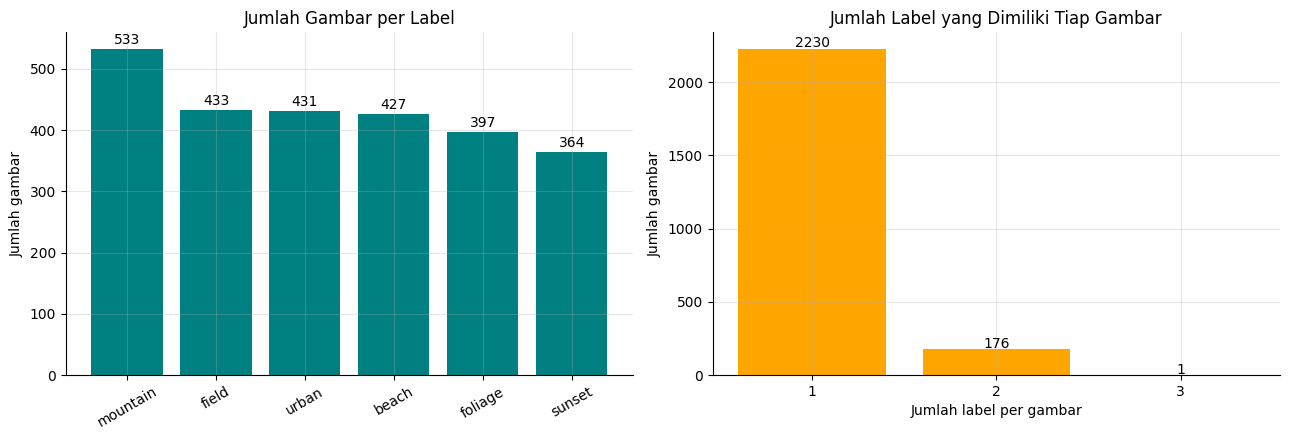

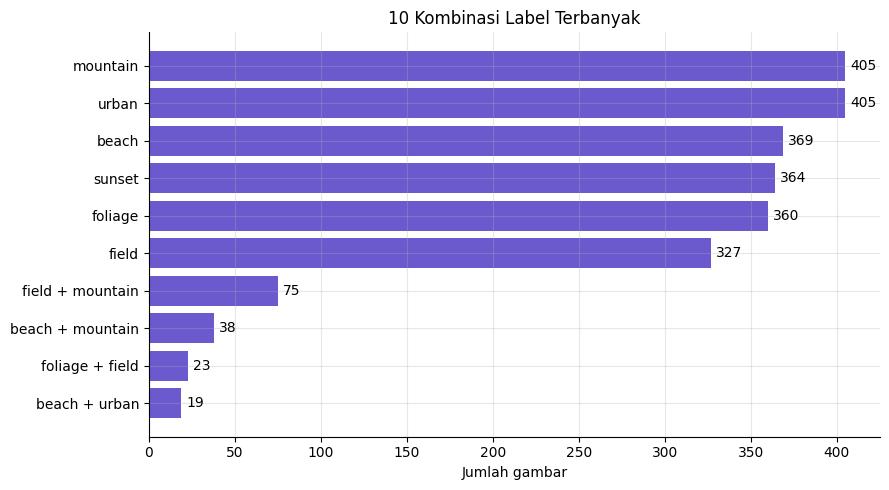

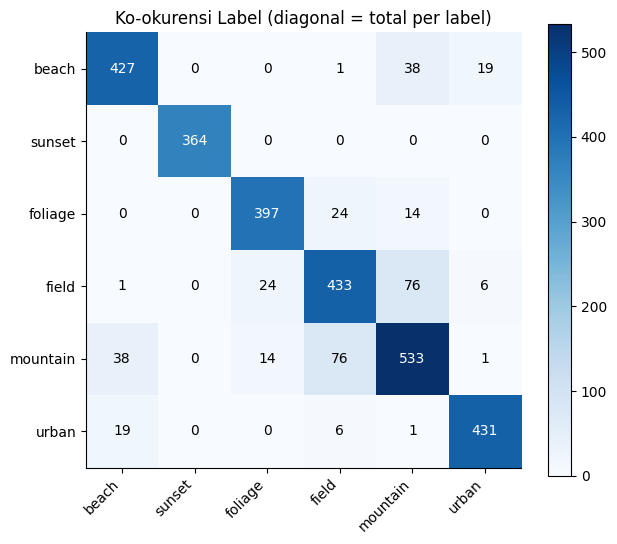

C:\Users\kholilah\AppData\Local\Temp\ipykernel_25560\1316705562.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].set_title('PCA 2D untuk Beberapa Label'); ax[1].set_xlabel('PC1'); ax[1].legend()


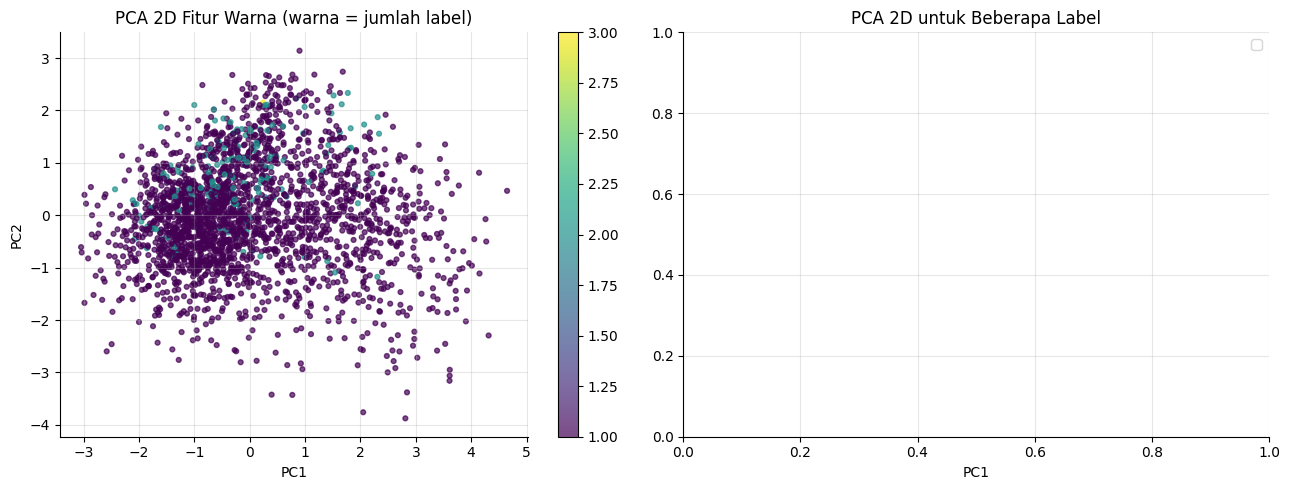

In [10]:
from collections import Counter

# --- 4a. Jumlah gambar per label + jumlah label per gambar
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
per_label = df[target].sum().sort_values(ascending=False)
ax[0].bar(per_label.index, per_label.values, color='teal')
for i, v in enumerate(per_label.values):
    ax[0].text(i, v + 8, str(v), ha='center')
ax[0].set_title('Jumlah Gambar per Label'); ax[0].set_ylabel('Jumlah gambar')
ax[0].tick_params(axis='x', rotation=30)

hit = pd.Series(jml).value_counts().sort_index()
ax[1].bar(hit.index.astype(str), hit.values, color='orange')
for i, v in enumerate(hit.values):
    ax[1].text(i, v + 8, str(v), ha='center')
ax[1].set_title('Jumlah Label yang Dimiliki Tiap Gambar')
ax[1].set_xlabel('Jumlah label per gambar'); ax[1].set_ylabel('Jumlah gambar')
plt.tight_layout(); plt.show()

# --- 4b. Kombinasi label yang paling sering muncul
kombinasi = Counter(map(tuple, Yarr))
def nama_kombinasi(k):
    n = [nm for nm, v in zip(target, k) if v]
    return ' + '.join(n) if n else '(tanpa label)'
top = kombinasi.most_common(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([nama_kombinasi(k) for k, _ in top], [c for _, c in top], color='slateblue')
for i, (_, c) in enumerate(top):
    ax.text(c + 3, i, str(c), va='center')
ax.set_title('10 Kombinasi Label Terbanyak'); ax.set_xlabel('Jumlah gambar')
plt.tight_layout(); plt.show()

# --- 4c. Heatmap ko-okurensi label (label mana yang sering muncul bersamaan)
co = Yarr.T @ Yarr
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(co, cmap='Blues')
ax.set_xticks(range(len(target))); ax.set_xticklabels(target, rotation=45, ha='right')
ax.set_yticks(range(len(target))); ax.set_yticklabels(target)
for i in range(len(target)):
    for j in range(len(target)):
        ax.text(j, i, int(co[i, j]), ha='center', va='center',
                color='white' if co[i, j] > co.max() / 2 else 'black')
ax.grid(False); ax.set_title('Ko-okurensi Label (diagonal = total per label)')
plt.colorbar(im); plt.tight_layout(); plt.show()

# --- 4d. Proyeksi PCA 2D fitur warna, diwarnai jumlah label
from sklearn.decomposition import PCA
Z = PCA(n_components=2, random_state=0).fit_transform(df[fitur])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sc = ax[0].scatter(Z[:, 0], Z[:, 1], c=jml, cmap='viridis', s=12, alpha=0.7)
ax[0].set_title('PCA 2D Fitur Warna (warna = jumlah label)')
ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2'); plt.colorbar(sc, ax=ax[0])

for lb in ['Beach', 'Sunset', 'Urban']:
    if lb in target:
        m = df[lb].values == 1
        ax[1].scatter(Z[m, 0], Z[m, 1], s=12, alpha=0.5, label=lb)
ax[1].set_title('PCA 2D untuk Beberapa Label'); ax[1].set_xlabel('PC1'); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Kesimpulan

- **Fitur (X):** fitur warna hasil ekstraksi dari gambar
- **Target (y):** 6 kolom biner (Beach, Sunset, FallFoliage, Field, Mountain, Urban)
- **Jenis data: Gambar** (sudah dalam bentuk fitur numerik)
- **Jenis klasifikasi: Multilabel** — satu gambar dapat memiliki lebih dari satu label sekaligus (rata-rata label per gambar > 1 pada sebagian data), berbeda dengan multikelas yang hanya satu kelas per sampel.